# Un balance en 19 bandas de tiempo: la brecha de repreciación, la brecha de duración y un primer EVE

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** los cuadernos 01 a 04 del tema 01 (el motor, un `TestResult`, las políticas)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este cuaderno puedes:

- ubicar los flujos de un balance en las 19 bandas de tiempo estándar y decir por qué existen las bandas;
- leer una brecha de repreciación y el efecto de primer orden de un cambio de tasa sobre el margen neto de intereses (NII), y decir qué deja fuera;
- leer una brecha de duración y el efecto de primer orden sobre el valor del patrimonio, y decir qué deja fuera;
- descontar los flujos netos hasta un valor económico del patrimonio (EVE) y explicar por qué el EVE es una medida de valor presente y no contable;
- comparar cada recálculo con el valor versionado, nombrando la versión del motor que lo calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, slotting

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son la fecha de valoración 2022-06-30 (2022-Q2) del caso C14, el riesgo de tasa de interés en el libro de banca (IRRBB) del banco que quebró en marzo de 2023, tal como Contraste lo versiona. Lo alimentan dos fuentes, ambas de la clase de licencia `mirror-allowed` (`conventions/third-party-datasets.md`):

- los **reportes de condición (call reports) de la FDIC** del banco (estados financieros de FDIC BankFind, https://api.fdic.gov/banks/financials, dominio público), que dan el balance por banda de reprecio;
- la **curva diaria de rendimientos a la par del Tesoro de EE. UU.** (https://home.treasury.gov/resource-center/data-chart-center/interest-rates, dominio público), que da las tasas con que se descuentan los flujos.

El banco es **real en agregado y sintético en comportamiento**: los totales son los del propio banco, pero el reporte no trae comportamiento de depósitos, ni historial de prepagos, ni un perfil más fino que sus bandas, así que todo supuesto de ese tipo lo declara Contraste y queda rotulado como sintético en el documento. El dinero está en miles de USD, las tasas son decimales con capitalización continua, y un delta EVE o delta NII positivo es una **pérdida**.

- **Archivos que se leen:** `data/derived/C14/vd-2022-q2.json` (`outputs.balance_sheet`, `ladder`, `curve`, `scenarios`, `units`, `sign_convention`) y `data/derived/C14/models-svb-2021-2022.json` (las etiquetas bilingües de las 19 bandas).

La celda siguiente carga los dos archivos e imprime lo que el documento dice de sí mismo.

In [2]:
# Cargar la fecha de valoración y el documento de modelos (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C14"
doc = json.loads((derived / "vd-2022-q2.json").read_text(encoding="utf-8"))
models = json.loads((derived / "models-svb-2021-2022.json").read_text(encoding="utf-8"))
out = doc["outputs"]
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
# Nombres en este idioma de los valores propios del documento (los identificadores del archivo quedan como están)
NAME = {"behavioural": "conductual", "contractual": "contractual", "asset": "activo", "liability": "pasivo",
        "real": "real", "synthetic": "sintético", "thousands": "miles", True: "sí", False: "no"}

print("fecha de valoración:", out["valuation_date"], "| moneda:", out["currency"], "| escala monetaria:", NAME[out["units"]["money_scale"]])
print("banco:", out["bank"]["name"], "| agregados:", NAME[out["bank"]["aggregates"]], "| comportamiento:", NAME[out["bank"]["behaviour"]])
print(out["bank"]["notice"][LANG])
print(out["sign_convention"]["statement"][LANG])
print("calculado por riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

fecha de valoración: 2022-06-30 | moneda: USD | escala monetaria: miles
banco: Silicon Valley Bank | agregados: real | comportamiento: sintético
Los agregados del reporte son los del banco, leídos de los estados financieros de FDIC BankFind. Todo supuesto de comportamiento (proporción y plazo estables de los depósitos, prepago, rescate de depósitos a plazo, la distribución de las bandas del reporte) es sintético y está declarado en el documento.
Un delta EVE o delta NII positivo es una pérdida; solo las pérdidas se agregan entre monedas.
calculado por riskvalidation 0.9.0 | instalado 0.9.0


## Método

El método tiene cinco pasos: (1) las 19 bandas, (2) ubicar flujos en ellas, (3) la brecha de repreciación y su efecto de primer orden sobre el NII, (4) la brecha de duración, (5) el EVE. Cada número es una llamada al motor; el cuaderno arma los insumos desde el documento versionado y compara cada resultado con lo que el documento trae.

### Paso 1: las 19 bandas de tiempo

El marco estandarizado del Comité de Basilea ubica todo flujo sensible a la tasa de interés en 19 bandas de tiempo, desde a la vista hasta más de 20 años, y representa cada banda por su punto medio (BCBS, SRP31.96, Tabla 3, https://www.bis.org/basel_framework/chapter/SRP/31.htm). Una banda es un intervalo $(\text{inferior}, \text{superior}]$: un flujo exactamente a un mes cae en la primera banda que termina en un mes. La función `bucket_grid` del motor devuelve los bordes, los puntos medios y las etiquetas. La celda siguiente imprime la grilla.

In [3]:
# La grilla de 19 bandas del motor: el número de la banda, sus bordes y su punto medio en años
grid = slotting.bucket_grid()
MID = grid.midpoints
print("bandas:", len(MID))
print(f"{'banda':>6s} {'inferior (a)':>14s} {'superior (a)':>14s} {'medio (a)':>14s}")
for k in range(len(MID)):
    print(f"{k + 1:6d} {grid.lower[k]:14.4f} {grid.upper[k]:14.4f} {MID[k]:14.4f}")

bandas: 19
 banda   inferior (a)   superior (a)      medio (a)
     1         0.0000         0.0028         0.0028
     2         0.0028         0.0833         0.0417
     3         0.0833         0.2500         0.1667
     4         0.2500         0.5000         0.3750
     5         0.5000         0.7500         0.6250
     6         0.7500         1.0000         0.8750
     7         1.0000         1.5000         1.2500
     8         1.5000         2.0000         1.7500
     9         2.0000         3.0000         2.5000
    10         3.0000         4.0000         3.5000
    11         4.0000         5.0000         4.5000
    12         5.0000         6.0000         5.5000
    13         6.0000         7.0000         6.5000
    14         7.0000         8.0000         7.5000
    15         8.0000         9.0000         8.5000
    16         9.0000        10.0000         9.5000
    17        10.0000        15.0000        12.5000
    18        15.0000        20.0000        17.5000
 

### Paso 2: ubicar los flujos en las bandas

`bucket_of` da el número de banda de un plazo y `slot_cash_flows` suma una lista de montos en plazos dados dentro de las 19 bandas (activos positivos, pasivos negativos); la suma del resultado es igual a la suma de los montos, así que ubicar mueve dinero entre bandas y nunca lo crea ni lo destruye. La celda siguiente ubica un ejemplo pequeño con plazos elegidos a mano: un préstamo bullet de 1.000 que vence en 5 años, un depósito de 400 que reprecia en 2,3 años y un depósito de 300 que reprecia exactamente en un mes.

In [4]:
# Ubicar tres flujos a mano: la banda de cada plazo, luego el vector de 19 bandas y la conservación del dinero
times = np.array([5.0, 2.3, 1 / 12])
amounts = np.array([1000.0, -400.0, -300.0])
for t, a in zip(times, amounts):
    print(f"plazo {t:7.4f} años, monto {a:8.1f} -> banda {slotting.bucket_of(t, grid)}")
slotted = slotting.slot_cash_flows(times, amounts, grid)
print("bandas con monto:", {k + 1: float(v) for k, v in enumerate(slotted) if v != 0.0})
print("suma de los flujos ubicados:", float(slotted.sum()), "| suma de los montos:", float(amounts.sum()))

plazo  5.0000 años, monto   1000.0 -> banda 11
plazo  2.3000 años, monto   -400.0 -> banda 9
plazo  0.0833 años, monto   -300.0 -> banda 2
bandas con monto: {2: -300.0, 9: -400.0, 11: 1000.0}
suma de los flujos ubicados: 300.0 | suma de los montos: 300.0


### El balance versionado

El balance del banco tiene 17 partidas (8 activos y 9 pasivos). El pipeline ubicó cada una en las 19 bandas con el motor y versionó el resultado dos veces: con el tratamiento **conductual** de los depósitos a la vista (la parte que el estándar llama estable se reparte en el tiempo, con los topes del estándar) y con el tratamiento **contractual** (todo depósito a la vista a un día). La celda siguiente lista las partidas con sus montos y verifica que los totales del documento son la suma de las partidas.

In [5]:
# Listar las partidas del balance y verificar los totales del documento contra la suma de las partidas
items = out["balance_sheet"]["items"]
for it in items:
    print(f"{it['item_id']:4s} {NAME[it['side']]:9s} {it['amount']:16,.0f}  {it['label'][LANG]}")
assets = sum(it["amount"] for it in items if it["side"] == "asset")
liabilities = sum(it["amount"] for it in items if it["side"] == "liability")
print("activos:", round(assets), "| documento:", round(out["balance_sheet"]["total_assets"]))
print("pasivos:", round(liabilities), "| documento:", round(out["balance_sheet"]["total_liabilities"]))
print("patrimonio (activos menos pasivos):", round(assets - liabilities))

A1   activo          14,269,000  Efectivo y saldos en instituciones depositarias
A2   activo             539,000  Fondos federales vendidos y pactos de retroventa
A3   activo          95,814,000  Valores mantenidos al vencimiento
A4   activo          26,130,000  Valores disponibles para la venta
A5   activo          55,065,000  Préstamos con reprecio dentro de tres meses
A6   activo           7,748,000  Préstamos comerciales y otros de tasa fija
A7   activo           8,048,000  Préstamos residenciales a plazo (prepagables)
A8   activo           4,211,000  Otros activos, netos de provisión, y préstamos sin banda de reprecio
L1   pasivo           2,723,410  Depósitos sin interés, minoristas
L2   pasivo         113,453,590  Depósitos sin interés, mayoristas
L3   pasivo           1,726,590  Depósitos a la vista con interés, minoristas
L4   pasivo          71,927,410  Depósitos a la vista con interés, mayoristas
L5   pasivo             322,000  Depósitos a plazo
L6   pasivo           3,500,

El vector de 19 bandas de cada partida está en `cash_flows`. La celda siguiente reconstruye los vectores de los activos y de los pasivos bajo cada tratamiento: los pasivos se guardan con monto negativo y las funciones de brecha reciben magnitudes, así que el vector de pasivos es el negativo de la suma guardada. Verifica que el total de cada vector es la suma de las partidas, la conservación vista arriba, ahora sobre el balance real.

In [6]:
# Reconstruir los vectores de 19 bandas de activos y pasivos, conductual y contractual, desde las partidas versionadas
def to_vector(rows):
    vector = np.zeros(19)
    for row in rows:
        vector[row["bucket"] - 1] += row["amount"]
    return vector

flows = {}
for treatment in ("behavioural", "contractual"):
    a = sum(to_vector(it["cash_flows"][treatment]) for it in items if it["side"] == "asset")
    l = -sum(to_vector(it["cash_flows"][treatment]) for it in items if it["side"] == "liability")
    flows[treatment] = (a, l)
    print(f"{NAME[treatment]:12s} activos en las bandas {a.sum():16,.0f} | pasivos en las bandas {l.sum():16,.0f}")
print("partidas activos {:,.0f} | partidas pasivos {:,.0f}".format(assets, liabilities))

conductual   activos en las bandas      211,824,000 | pasivos en las bandas      196,438,000
contractual  activos en las bandas      211,824,000 | pasivos en las bandas      196,438,000
partidas activos 211,824,000 | partidas pasivos 196,438,000


### Paso 3: la brecha de repreciación y el efecto de primer orden sobre el NII

La brecha de repreciación de la banda $k$ son los activos menos los pasivos que reprecian en ella, $G_k = RSA_k - RSL_k$, en dinero. Para un cambio paralelo $\Delta r$ y un horizonte de un año con balance constante, la aproximación de libro de texto del cambio en el NII por brechas es

$$\Delta NII \approx \sum_{t_k < 1} G_k \,\Delta r\, (1 - t_k)$$

donde $t_k$ es el punto medio de la banda $k$ en años: una brecha que reprecia temprano gana la nueva tasa el resto del año. Ignora el riesgo de base, las opciones y el negocio nuevo (fuente: dossier 05, D.1, y la literatura de brechas de ganancias; BCBS exige la sensibilidad del NII bajo los dos escenarios paralelos para la divulgación, d368). La función `delta_nii_gap` del motor lo informa **con la pérdida positiva**, así que una brecha positiva gana más cuando suben las tasas y devuelve un número negativo. La celda siguiente llama a `repricing_gap` y a `delta_nii_gap` para un cambio de +100 pb y compara con la escalera versionada.

In [7]:
# Brecha de reprecio por banda y su efecto de primer orden sobre el NII para +100 pb, conductual y contractual, contra la escalera versionada
ladder = {row["nmd_assumption"]: row for row in out["ladder"]}
gaps = {}
for treatment, (a, l) in flows.items():
    gaps[treatment] = eve_nii.repricing_gap(a, l)
    committed = np.array([r["gap"] for r in ladder[treatment]["repricing_gap"]])
    d_nii = eve_nii.delta_nii_gap(gaps[treatment], MID, 100.0)
    biggest = int(np.argmax(np.abs(gaps[treatment])))
    print(f"{NAME[treatment]:12s} mayor brecha {gaps[treatment][biggest]:16,.0f} en la banda {biggest + 1}")
    print(f"{'':12s} brecha igual a la versionada: {NAME[bool(np.allclose(gaps[treatment], committed))]}")
    print(f"{'':12s} delta NII para +100 pb (pérdida positiva): {d_nii:14,.0f} | versionado {ladder[treatment]['delta_nii_gap_100bp_up']:14,.0f}")

conductual   mayor brecha      -76,433,446 en la banda 1
             brecha igual a la versionada: sí
             delta NII para +100 pb (pérdida positiva):        199,057 | versionado        199,057
contractual  mayor brecha     -172,807,898 en la banda 1
             brecha igual a la versionada: sí
             delta NII para +100 pb (pérdida positiva):      1,199,488 | versionado      1,199,488


El efecto es la suma de las contribuciones de las seis primeras bandas, las de punto medio menor a un año. La celda siguiente muestra cada contribución para la brecha conductual, para que el lector vea qué banda empuja el resultado: la brecha a la vista es grande y negativa (los depósitos que reprecian de inmediato), pero su peso $1 - t_k$ es casi uno, así que domina. Es una verificación de la definición sobre el balance real, no una segunda implementación de la función; el motor sigue siendo el método.

In [8]:
# Contribución de cada banda bajo un año al delta NII con pérdida positiva para +100 pb (verificación de la definición)
gap = gaps["behavioural"]
near = MID < 1.0
contribution = -gap * 0.01 * (1.0 - MID)
for k in np.flatnonzero(near):
    print(f"banda {k + 1:2d} medio {MID[k]:7.4f} brecha {gap[k]:16,.0f} peso {1 - MID[k]:7.4f} contribución {contribution[k]:14,.0f}")
print("suma de las contribuciones:", round(float(contribution[near].sum())))
print("igual al motor:", NAME[bool(np.isclose(contribution[near].sum(), eve_nii.delta_nii_gap(gap, MID, 100.0)))])

banda  1 medio  0.0028 brecha      -76,433,446 peso  0.9972 contribución        762,194
banda  2 medio  0.0417 brecha       19,035,377 peso  0.9583 contribución       -182,416
banda  3 medio  0.1667 brecha       39,236,232 peso  0.8333 contribución       -326,956
banda  4 medio  0.3750 brecha        4,907,151 peso  0.6250 contribución        -30,670
banda  5 medio  0.6250 brecha        4,668,329 peso  0.3750 contribución        -17,506
banda  6 medio  0.8750 brecha        4,471,798 peso  0.1250 contribución         -5,590
suma de las contribuciones: 199057
igual al motor: sí


### Paso 4: la brecha de duración y el efecto de primer orden sobre el patrimonio

La brecha de duración compara cuánto tardan los activos y los pasivos, ponderados por valor, en pagarse en valor presente. Con el valor presente de los activos $A$ y de los pasivos $L$, y sus duraciones ponderadas por valor $D_A$ y $D_L$,

$$DGAP = D_A - \frac{L}{A}\, D_L, \qquad \Delta E \approx -DGAP \cdot A \cdot \Delta y$$

(fuente: dossier 05, D.2: una aproximación de primer orden de libro de texto sin una única fuente primaria). Con capitalización continua la duración modificada es igual a la de Macaulay, el tiempo promedio ponderado por valor. Una brecha positiva significa que los activos son más largos que los pasivos, así que una suba de tasas baja el patrimonio. La función `duration_gap` del motor necesita los flujos, las tasas cero en los puntos medios y los puntos medios; primero hacen falta las tasas.

#### La curva cero

El Tesoro publica **rendimientos a la par** en 12 plazos; descontar necesita **tasas cero**. La función `bootstrap_zero_curve` del motor convierte los rendimientos a la par en tasas cero con capitalización continua (cupones semestrales de equivalente bono, interés simple hasta seis meses), y `zero_rates_at` las interpola linealmente en el plazo, planas fuera de la grilla, en los 19 puntos medios. La celda siguiente repite ambos pasos desde los rendimientos observados versionados y compara con las tasas cero que trae el documento.

In [9]:
# Construir la curva cero desde los rendimientos a la par observados y leerla en los 19 puntos medios, contra las tasas cero versionadas
points = out["curve"]["points"]
tenors = np.array([p["tenor_years"] for p in points])
par = np.array([p["observed_yield"] for p in points])
zero = curves.bootstrap_zero_curve(tenors, par, 2)
r0 = curves.zero_rates_at(tenors, zero, MID)
print("tipo de curva:", out["curve"]["observed_kind"], "| plazos:", len(tenors), "| plazo faltante (años):", out["curve"]["missing_tenors"])
print("tasas cero iguales a las versionadas en los plazos:", NAME[bool(np.allclose(zero, [p["zero_rate"] for p in points]))])
print("tasas cero iguales a las versionadas en los puntos medios:", NAME[bool(np.allclose(r0, out["curve"]["zero_rates_at_midpoints"]))])
for k in (0, 5, 9, 14, 18):
    print(f"banda {k + 1:2d} medio {MID[k]:7.4f} tasa cero {r0[k]:.5f}")

tipo de curva: par-yield | plazos: 12 | plazo faltante (años): [0.333333]
tasas cero iguales a las versionadas en los plazos: sí
tasas cero iguales a las versionadas en los puntos medios: sí
banda  1 medio  0.0028 tasa cero 0.01279
banda  6 medio  0.8750 tasa cero 0.02711
banda 10 medio  3.5000 tasa cero 0.02977
banda 15 medio  8.5000 tasa cero 0.02988
banda 19 medio 25.0000 tasa cero 0.03257


#### La brecha de duración sobre el balance real

Ahora la brecha de duración, para el tratamiento conductual y para el contractual. Los dos tratamientos difieren en los pasivos: con todo depósito a la vista a un día, los pasivos casi no tienen duración y los activos son mucho más largos, así que la brecha es grande.

In [10]:
# Brecha de duración del balance bajo cada tratamiento, contra la escalera versionada
for treatment, (a, l) in flows.items():
    dg = eve_nii.duration_gap(a, l, r0, MID)
    c = ladder[treatment]["duration_gap"]
    print(NAME[treatment])
    print(f"  VP de activos {dg.asset_value:16,.0f} | VP de pasivos {dg.liability_value:16,.0f}")
    print(f"  duración de activos (a) {dg.asset_duration_years:7.4f} | duración de pasivos (a) {dg.liability_duration_years:7.4f}")
    print(f"  brecha de duración (a) {dg.duration_gap_years:7.4f} | cambio del patrimonio para +100 pb {dg.equity_change_100bp_up:14,.0f}")
    print("  igual a los valores versionados:", NAME[bool(np.isclose(dg.duration_gap_years, c["duration_gap_years"]) and np.isclose(dg.equity_change_100bp_up, c["equity_change_100bp_up"]))])

conductual
  VP de activos      192,515,579 | VP de pasivos      185,478,799
  duración de activos (a)  2.8407 | duración de pasivos (a)  1.8656
  brecha de duración (a)  1.0433 | cambio del patrimonio para +100 pb     -2,008,492
  igual a los valores versionados: sí
contractual
  VP de activos      185,093,900 | VP de pasivos      196,381,326
  duración de activos (a)  3.8215 | duración de pasivos (a)  0.0128
  brecha de duración (a)  3.8079 | cambio del patrimonio para +100 pb     -7,048,257
  igual a los valores versionados: sí


### Paso 5: el valor económico del patrimonio

El EVE es el valor presente de los flujos netos: los activos menos los pasivos, cada uno descontado a su tasa cero. Con los flujos netos $CF_k$ (activos positivos, pasivos negativos) y las tasas cero $R_k$ en los puntos medios (BCBS SRP31.129; dossier 05, D.2):

$$DF_k = \exp(-R_k\, t_k), \qquad EVE = \sum_{k=1}^{19} CF_k \, DF_k$$

Es una medida de **valor presente**: pregunta cuánto vale hoy el balance si cada flujo se paga como se ubicó, no lo que dicen los libros. Por eso puede estar lejos del patrimonio contable, y por eso el tratamiento de los depósitos, que los libros llevan a la par, lo mueve tanto. La celda siguiente calcula los factores de descuento con `discount_factors` y el EVE con `eve`, y compara con el EVE base de los escenarios versionados.

In [11]:
# Factores de descuento y EVE base bajo cada tratamiento, contra el EVE base versionado de los escenarios
df = curves.discount_factors(r0, MID)
print("factores de descuento en las bandas 1, 10 y 19:", [round(float(df[k]), 6) for k in (0, 9, 18)])
base = {}
for treatment, (a, l) in flows.items():
    base[treatment] = eve_nii.eve(a - l, r0, MID)
    committed = next(s["base_eve"] for s in out["scenarios"] if s["calibration"] == "2024" and s["nmd_assumption"] == treatment)
    print(f"{NAME[treatment]:12s} EVE {base[treatment]:16,.0f} | versionado {committed:16,.0f} | igual {NAME[bool(np.isclose(base[treatment], committed))]}")
print("patrimonio contable:", round(assets - liabilities))

factores de descuento en las bandas 1, 10 y 19: [0.999964, 0.901054, 0.442993]
conductual   EVE        7,036,780 | versionado        7,036,780 | igual sí
contractual  EVE      -11,287,425 | versionado      -11,287,425 | igual sí
patrimonio contable: 15386000


La última celda dibuja la brecha por banda para los dos tratamientos y la curva cero. A la izquierda la brecha conductual muestra la gran brecha negativa a la vista, que son los depósitos que reprecian, y los activos largos positivos; la brecha contractual es el mismo balance con todo depósito a la vista a un día, así que la brecha a la vista es mucho más negativa. A la derecha la curva cero en los 19 puntos medios, las tasas que descuentan todo flujo.

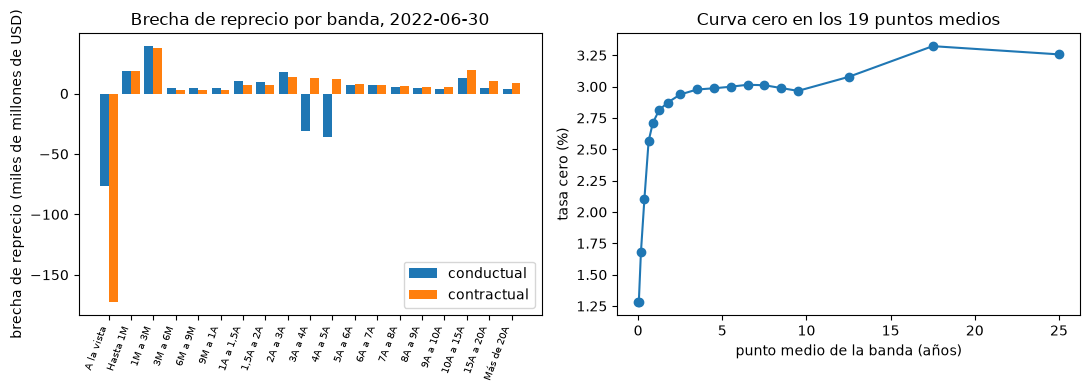

In [12]:
# Dibujar la brecha de reprecio por banda para los dos tratamientos y la curva cero en los puntos medios
labels = [b["label"][LANG] for b in models["fit"]["buckets"]]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
width = 0.4
x = np.arange(19)
left.bar(x - width / 2, gaps["behavioural"] / 1e6, width, label="conductual")
left.bar(x + width / 2, gaps["contractual"] / 1e6, width, label="contractual")
left.set_xticks(x)
left.set_xticklabels(labels, rotation=70, ha="right", fontsize=7)
left.set_ylabel("brecha de reprecio (miles de millones de USD)")
left.set_title("Brecha de reprecio por banda, 2022-06-30")
left.legend()
right.plot(MID, r0 * 100, marker="o")
right.set_xlabel("punto medio de la banda (años)")
right.set_ylabel("tasa cero (%)")
right.set_title("Curva cero en los 19 puntos medios")
fig.tight_layout()
plt.show()

## Resultados

- **Ubicación.** El ejemplo de tres flujos cae en las bandas 11, 9 y 2, y su total, 300, no cambia. En el banco, 211.824.000 de activos y 196.438.000 de pasivos (miles de USD) están en las bandas bajo ambos tratamientos: el tratamiento de los depósitos a la vista cambia dónde están los pasivos, nunca cuánto hay.
- **Brecha de repreciación y NII.** Con el tratamiento conductual la mayor brecha es -76.433.446 en la banda a la vista y el cambio de primer orden del NII para +100 pb es una pérdida de 199.057, igual al valor versionado. Con todo depósito a un día la brecha de esa banda es -172.807.898 y la pérdida es 1.199.488. La banda a la vista aporta una pérdida de 762.194 y las otras cinco bandas bajo un año devuelven unos 563.000, así que el neto de 199.057 es la diferencia de números mayores: un validador lee la escalera completa, no solo su suma. La aproximación mantiene constante el balance, usa un mismo desplazamiento para todas las bandas e ignora las opciones.
- **Brecha de duración.** La brecha de duración conductual es 1,0433 años y el cambio de primer orden del patrimonio para +100 pb es -2.008.492, el 13 por ciento del patrimonio contable de 15.386.000. La brecha contractual es 3,8079 años y el cambio es -7.048.257, el 46 por ciento. Ambos números son de primer orden: dicen hacia dónde y aproximadamente cuánto, no cuánto exactamente, y no pueden ver los pisos, las opciones ni un choque no paralelo.
- **EVE.** El EVE base es 7.036.780 con el tratamiento conductual y -11.287.425 con el contractual, frente a 15.386.000 de patrimonio contable. El EVE es un valor presente de los flujos tal como se ubicaron, por eso difiere del patrimonio contable, y toda la distancia entre los dos EVE viene de un supuesto, cuánto tiempo permanecen los depósitos a la vista. El cuaderno 03 desarma ese supuesto.
- **Lo que el cuaderno no muestra.** Los seis choques del estándar (cuaderno 02) y los supuestos de comportamiento detrás de la parte estable de los depósitos (cuaderno 03). El documento lo calculó el motor 0.8.1, la versión instalada, así que cada recálculo es igual a su valor versionado; el cuaderno imprime ambas versiones para que un lector con otro motor vea la diferencia.

## Resumen

- Un balance se vuelve 19 números por lado: ubicar mueve cada flujo a la banda de su plazo de reprecio o vencimiento y nunca cambia el total.
- La brecha de repreciación es activos menos pasivos por banda; su efecto de primer orden sobre el NII conserva solo las bandas bajo un año, ponderadas por el tiempo que queda del año.
- La brecha de duración es la diferencia entre las duraciones ponderadas por valor de activos y pasivos, escalada por el apalancamiento; da el efecto de primer orden sobre el patrimonio.
- El EVE es un valor presente, y el tratamiento de los depósitos a la vista lo mueve más que el patrimonio de los libros.
- Las dos aproximaciones son de primer orden e ignoran opciones y riesgo de base; los cuadernos siguientes las reemplazan por los seis choques del estándar y por la capa de comportamiento.

**Qué probar a continuación.** Cambia el desplazamiento de +100 pb de `delta_nii_gap` por -100 pb y lee el signo. Después sigue con el cuaderno 02, los seis choques estándar.

## Referencias

- BCBS, Standards: Interest rate risk in the banking book, SRP31, Tabla 3 (las 19 bandas de tiempo) y SRP31.129 (el EVE estandarizado). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book. https://www.bis.org/bcbs/publ/d368.htm
- FDIC, BankFind financials (reportes de condición), dominio público. https://api.fdic.gov/banks/financials
- Departamento del Tesoro de EE. UU., Daily Treasury Par Yield Curve Rates, dominio público. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 de la investigación de Contraste (modelos de IRRBB y ALM), secciones D.1 y D.2: las aproximaciones por brechas de ganancias y de duración.